# Pipeline Flow A: Preprocessing Reference Set
Questo notebook gestisce l'esecuzione sequenziale dei singoli moduli del Flow A.

Caricate con successo 8 monete: ['10cent', '1cent', '1euro', '20cent', '2cent', '2euro', '50cent', '5cent']


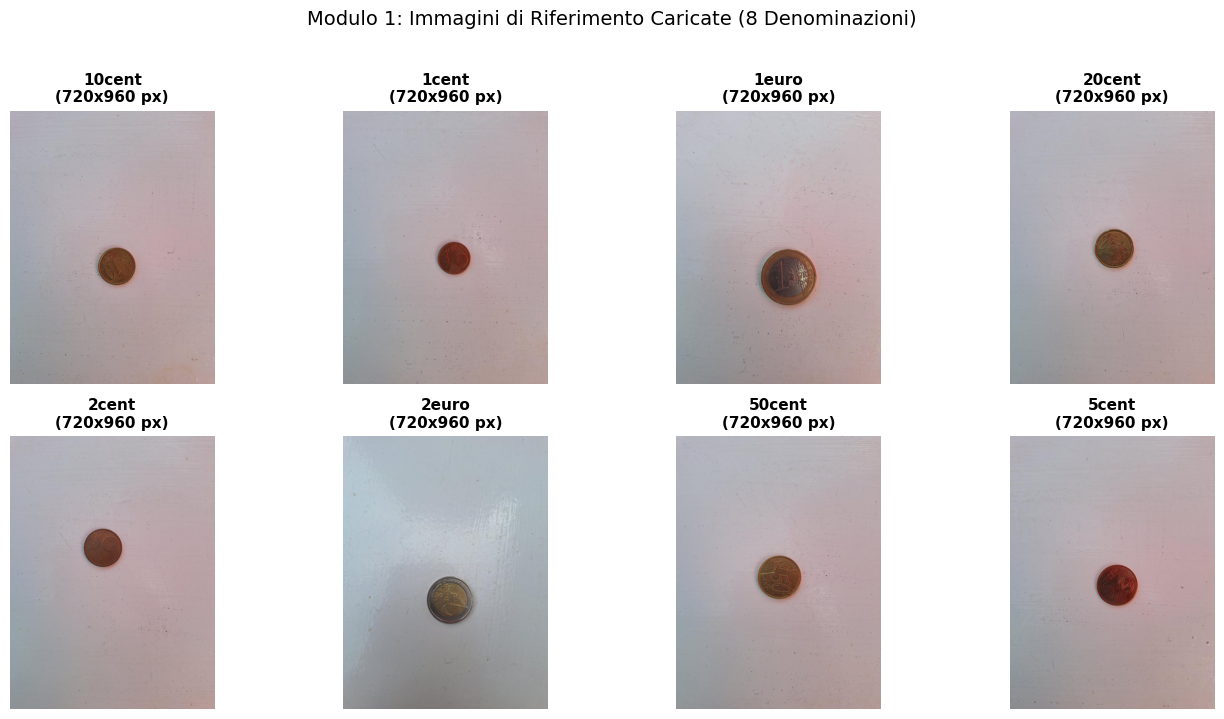

In [9]:
# ==========================================
# MODULO 1: Caricamento Immagini Reference
# ==========================================
from module1_load_references import load_reference_images, plot_reference_images

# Output in memoria: dizionario con le 8 immagini BGR delle monete
ref_images = load_reference_images()
print(f"Caricate con successo {len(ref_images)} monete: {list(ref_images.keys())}")

# Visualizzazione a schermo delle 8 monete
plot_reference_images(ref_images)


Salvate con successo 8 ROI in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module2_rois


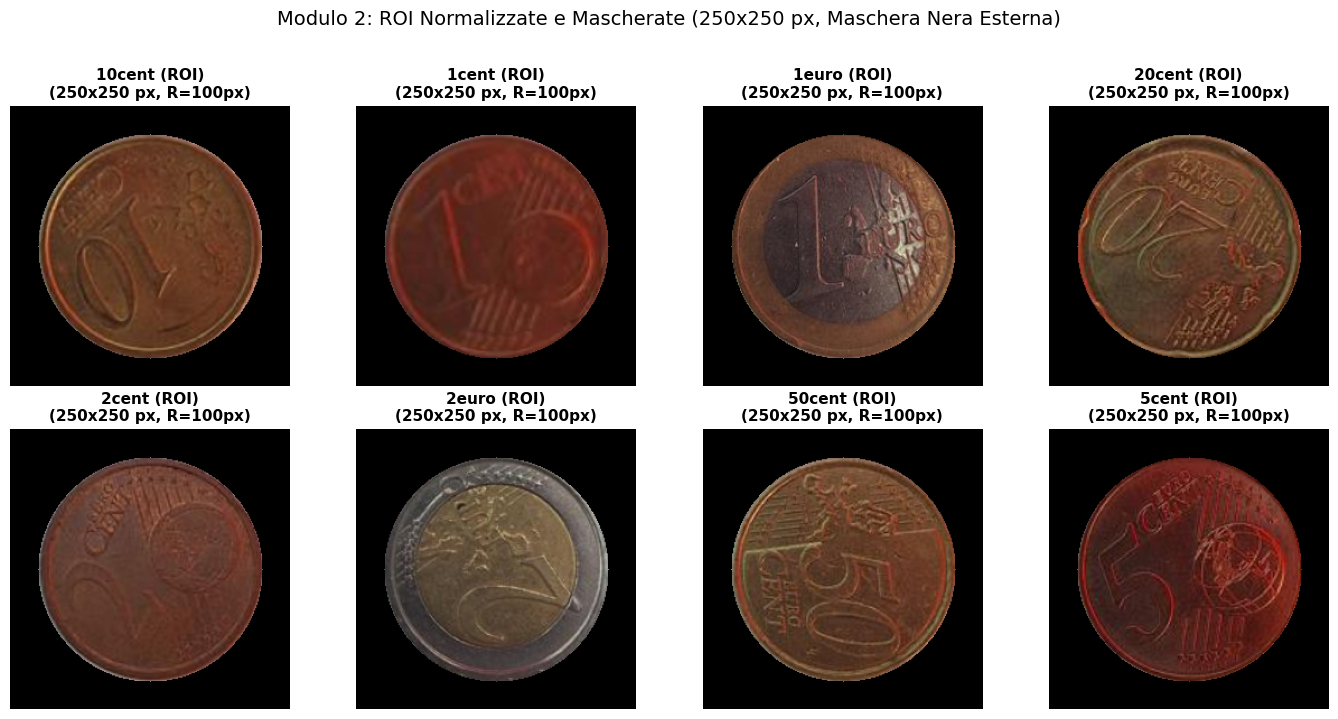

In [10]:
# ==========================================
# MODULO 2: Estrazione ROI Normalizzate e Mascherate
# ==========================================
from module2_extract_roi import extract_and_save_rois, plot_rois

# Input: ref_images (output del Modulo 1)
# Output in memoria: dizionario con le 8 ROI BGR mascherate (250x250 px, R=100px)
# Serializzazione: salvataggio su disco in artifacts/Flow_A_Reference/module2_rois/
ref_rois = extract_and_save_rois(ref_images)

# Visualizzazione a schermo delle 8 ROI mascherate
plot_rois(ref_rois)


Soglia bimetallica (Delta b*): 7.41  (half gap 5.08)
Soglia rame/oro (Hue):         21.7°  (half gap 4.2°)
Profili colore salvati con successo in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module3_color/color_profiles.json
Grafico profili colore salvato in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module3_color/color_profiles_plot.png


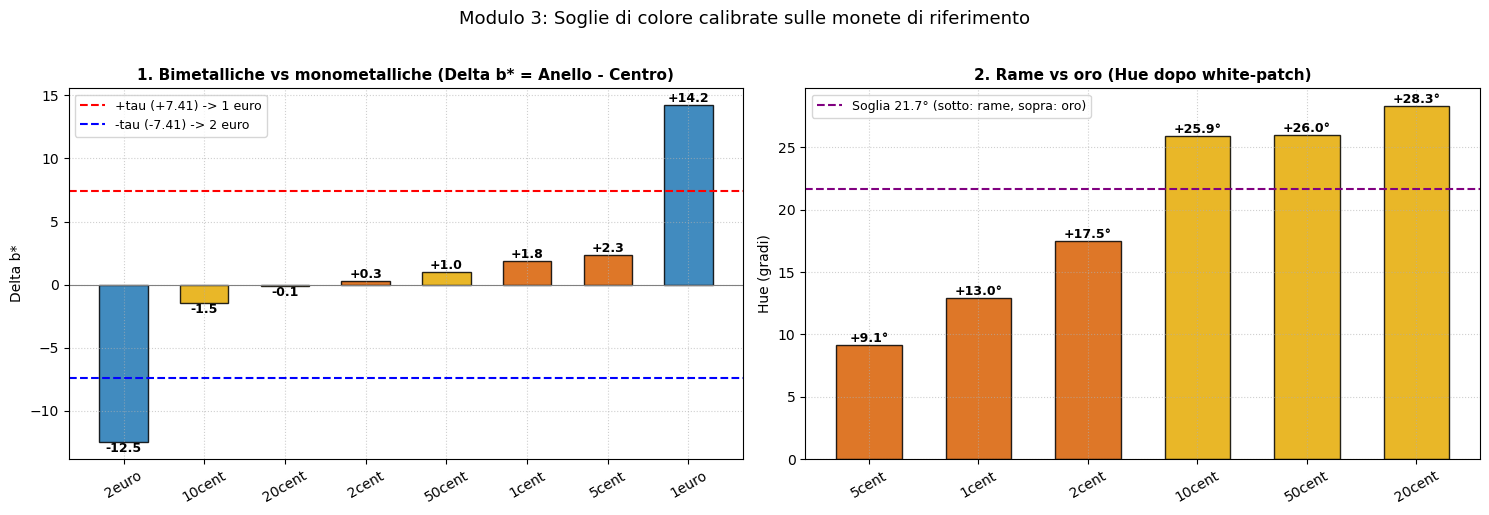

In [11]:
# ==========================================
# MODULO 3: Calibrazione delle Soglie di Colore sulle Reference
# ==========================================
import importlib
import module3_extract_color
importlib.reload(module3_extract_color)
from module3_extract_color import extract_and_save_color_profiles, plot_color_analysis

# Input: le 8 immagini di riferimento intere (il white-patch usa lo sfondo, quindi non le ROI mascherate)
# Output in memoria: color_profiles (soglie, half_gap e valori misurati su ogni reference)
#    - Delta b* (anello - centro): bimetalliche vs monometalliche, segno -> 1 euro / 2 euro
#    - Hue dopo white-patch: rame vs oro
# Serializzazione: salvataggio su file JSON in artifacts/Flow_A_Reference/module3_color/color_profiles.json
color_profiles = extract_and_save_color_profiles()

# Visualizzazione grafica dei valori delle reference e delle soglie che ne derivano
plot_color_analysis(color_profiles)

Salvate con successo 8 ROI Grayscale in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module4_rois_gray
Salvati 8 file edge PNG in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module4_edges e la configurazione in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/conf/Flow_A_Reference/edge_params.json
Grafico riassuntivo degli edge salvato in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module4_edges/all_edges_summary.png


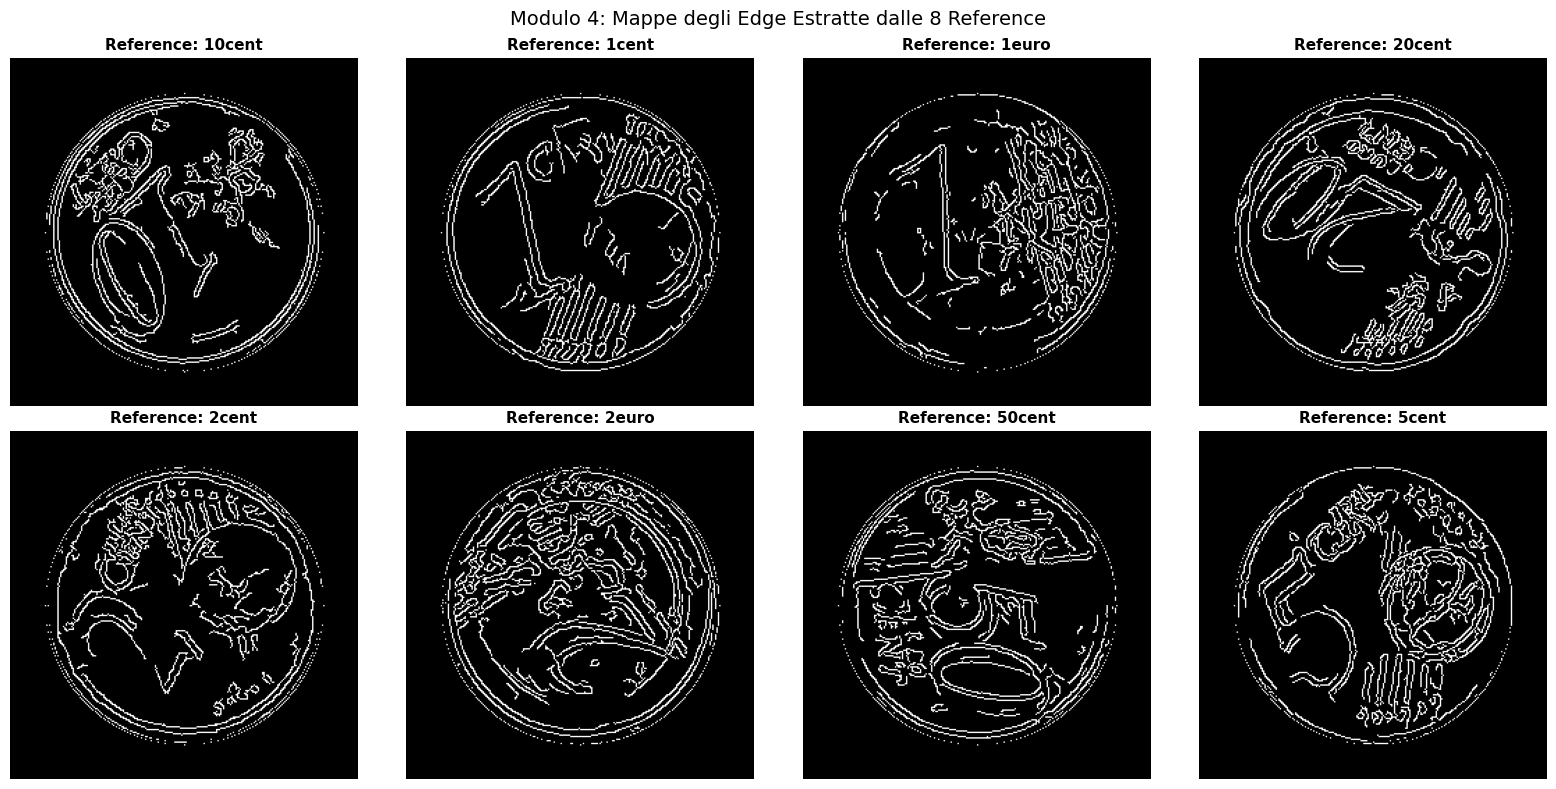

In [12]:
# ==========================================
# MODULO 4: Estrazione Edge (Parametri da conf/Flow_A_Reference/edge_params.json)
# ==========================================
from module4_extract_edges import (
    convert_and_save_gray_rois,
    load_or_create_edge_params,
    extract_and_save_all_edges,
    plot_all_edges
)

# 1. Conversione delle 8 ROI BGR in Grayscale e salvataggio su file
# Input: ref_rois (output in memoria del Modulo 2)
# Output in memoria: ref_rois_gray (dizionario {nome_moneta: roi_gray})
# Serializzazione: artifacts/Flow_A_Reference/module4_rois_gray/{nome}_gray.png
ref_rois_gray = convert_and_save_gray_rois(ref_rois)

# 2. Caricamento dei parametri configurati (da conf/Flow_A_Reference/edge_params.json)
# Nota: Il tuning interattivo è disponibile in conf/tuning/edge_tuning.ipynb
edge_params = load_or_create_edge_params()

# 3. Esecuzione batch: estrazione di tutte le 8 mappe di edge
# Output in memoria: ref_edges ({nome_moneta: edge_img})
# Serializzazione: artifacts/Flow_A_Reference/module4_edges/{nome}_edges.png
ref_edges = extract_and_save_all_edges(ref_rois_gray, edge_params)

# 4. Visualizzazione a schermo di tutti gli 8 edge estratti
plot_all_edges(ref_edges)


In [13]:
# ==========================================
# MODULO 5: Srotolamento Polare (Polar Unwarp / Angular Projection)
# ==========================================
from module5_polar_unwarp import (
    extract_and_save_all_polar,
    plot_all_polar_matrices,
    load_saved_polar_matrices
)

# Input: ref_edges (output in memoria del Modulo 4)
# Output in memoria: ref_polar_matrices (dizionario {nome_moneta: polar_matrix float32 (360x50)})
# Serializzazione in artifacts/Flow_A_Reference/module5_polar_unwarp/:
#   - Archivio compresso: polar_matrices.npz (pacchetto riutilizzabile da tutti i moduli successivi)
#   - File binari singoli: {nome}_polar.npy
#   - Immagini visive: {nome}_polar.png
#   - Metadati: polar_metadata.json
ref_polar_matrices = extract_and_save_all_polar(ref_edges)

# Visualizzazione a schermo delle 8 matrici polari estratte (Theta: 0°-360° vs Raggio: 0-50 bins)
plot_all_polar_matrices(ref_polar_matrices)


Salvate con successo 8 matrici polari in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module5_polar_unwarp
  - Archivio compresso NumPy: polar_matrices.npz
  - File array singoli .npy e visualizzazioni .png per ciascuna moneta
  - Metadati serializzati in: polar_metadata.json
Grafico riassuntivo delle matrici polari salvato in: /Users/juan/Desktop/2cents-X-IPCV/pipeline/artifacts/Flow_A_Reference/module5_polar_unwarp/all_polar_summary.png
